In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("gym_membership_dirty.csv")
df

,customer_id,age,gender,city,membership_type,price,workout_days_per_week,personal_trainer,referral_signup,membership_months,satisfaction_score,renewed
0,1,NaN,male,hyderabad,Premium,₹2360,5.0,NaN,No,24.0,1.6,Yes
1,2,-34.0,Male,Delhi,Premium,"5,926",1.0,1,no,3.0,3.9,yes
2,3,NaN,M,Chennai,Standard,Rs 78,2.0,N,No,12.0,3.4,Yes
3,4,59.0,male,Hyderabad,Standard,₹4404,4.0,1,No,3.0,1.2,NaN
4,5,31.0,female,Mumbai,Premium,₹76,5.0,no,Y,6.0,2.5,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
410,175,49.0,male,Pune,Basic,$3122,3.0,NaN,0,6.0,3.4,No
411,373,58.0,female,Hyderabad,Gold,$2189,3.0,N,NaN,3.0,3.9,1
412,189,30.0,male,Pune,Premium,"2,128",2.0,Y,NaN,3.0,2.7,No
413,325,36.0,Male,Chennai,Gold,67,1.0,0,no,12.0,2.5,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            415 non-null    int64  
 1   age                    391 non-null    float64
 2   gender                 350 non-null    str    
 3   city                   415 non-null    str    
 4   membership_type        415 non-null    str    
 5   price                  397 non-null    str    
 6   workout_days_per_week  394 non-null    float64
 7   personal_trainer       373 non-null    str    
 8   referral_signup        363 non-null    str    
 9   membership_months      356 non-null    float64
 10  satisfaction_score     382 non-null    float64
 11  renewed                355 non-null    str    
dtypes: float64(4), int64(1), str(7)
memory usage: 49.8 KB


In [4]:
df['age'].isna().sum()

np.int64(24)

In [5]:
df['age'] = df['age'].abs()
print(df['age'])

0       NaN
1      34.0
2       NaN
3      59.0
4      31.0
       ... 
410    49.0
411    58.0
412    30.0
413    36.0
414    52.0
Name: age, Length: 415, dtype: float64


In [6]:
df['age'] = df['age'].fillna(df['age'].median())
print(df['age'])

0      42.0
1      34.0
2      42.0
3      59.0
4      31.0
       ... 
410    49.0
411    58.0
412    30.0
413    36.0
414    52.0
Name: age, Length: 415, dtype: float64


In [7]:
df['gender'].unique()

<ArrowStringArray>
['male', 'Male', 'M', 'female', 'Female', nan, 'Other', 'F']
Length: 8, dtype: str

In [8]:
df['gender'] = df['gender'].str.replace('Male','male',regex=False)
df['gender'] = df['gender'].str.replace('Female','female',regex=False)
df['gender'] = df['gender'].str.replace('F','female',regex=False)
df['gender'] = df['gender'].str.replace('M','male',regex=False)
df['gender'] = df['gender'].fillna('unknown')

In [9]:
df['gender'].unique()

<ArrowStringArray>
['male', 'female', 'unknown', 'Other']
Length: 4, dtype: str

In [10]:
print(df['city'].isna().sum())
print(df['membership_type'].isna().sum())
print(df['membership_type'].unique())
print(df['city'].unique())

0
0
<ArrowStringArray>
['Premium', 'Standard', 'Standard ', 'PREMIUM', 'Gold', 'Basic', 'basic']
Length: 7, dtype: str
<ArrowStringArray>
['hyderabad',   '  Delhi',   'Chennai', 'Hyderabad',   'Mumbai ',      'Pune',
 'BANGALORE',    'Mumbai',     'Delhi', 'Bangalore']
Length: 10, dtype: str


In [11]:
df['membership_type'] = df['membership_type'].str.strip()
df['membership_type'] = df['membership_type'].str.replace('PREMIUM','Premium',regex=False)
df['membership_type'] = df['membership_type'].str.replace('Standard ','Standard',regex=False)
df['membership_type'] = df['membership_type'].str.replace('basic','Basic',regex=False)

In [12]:
df['city'] = df['city'].str.strip()
df['city'] = df['city'].str.replace('hyderabad','Hyderabad',regex=False)
df['city'] = df['city'].str.replace('Mumbai ','Mumbai',regex=False)
df['city'] = df['city'].str.replace('  Delhi','Delhi',regex=False)
df['city'] = df['city'].str.replace('BANGALORE','Bangalore',regex=False)

In [13]:
print(df['city'].isna().sum())
print(df['membership_type'].isna().sum())
print(df['membership_type'].unique())
print(df['city'].unique())

0
0
<ArrowStringArray>
['Premium', 'Standard', 'Gold', 'Basic']
Length: 4, dtype: str
<ArrowStringArray>
['Hyderabad', 'Delhi', 'Chennai', 'Mumbai', 'Pune', 'Bangalore']
Length: 6, dtype: str


In [14]:
print(df['price'].unique())
print("-----")
print(df['price'].isna().sum())

<ArrowStringArray>
[  '₹2360',   '5,926',   'Rs 78',   '₹4404',     '₹76', 'Rs 5056',   'Rs 23',
    '4056',      '18',   'Rs 76',
 ...
   '₹4424',      '46', 'Rs 5458',      '42',   '3,060',   'Rs 17', 'Rs 5331',
   '₹5933',    '3174',   '$5330']
Length: 326, dtype: str
-----
18


In [15]:
"""p = df['price'].str.strip()
p = p.str.replace('Rs ','',regex=False)
p = p.str.replace('₹','',regex=False)
p = p.str.replace('$','',regex=False)
p = p.str.replace(',','',regex=False)"""

"p = df['price'].str.strip()\np = p.str.replace('Rs ','',regex=False)\np = p.str.replace('₹','',regex=False)\np = p.str.replace('$','',regex=False)\np = p.str.replace(',','',regex=False)"

In [16]:
"""p = pd.to_numeric(p)
df['price'] = p
df['price'] = df['price'].fillna(df['price'].median())"""

"p = pd.to_numeric(p)\ndf['price'] = p\ndf['price'] = df['price'].fillna(df['price'].median())"

In [17]:
p = df['price'].str.strip()

is_usd = p.str.contains(r'\$', regex=True, na=False)

p = p.str.replace('Rs ', '', regex=False)
p = p.str.replace('₹', '', regex=False)
p = p.str.replace(r'\$', '', regex=True)
p = p.str.replace(',', '', regex=False)

p = pd.to_numeric(p)

p = p.where(~is_usd, p * 83)   # convert $ rows to INR

df['price'] = p
df['price'] = df['price'].fillna(df['price'].median())

In [18]:
print(df['price'])

0        2360.0
1        5926.0
2          78.0
3        4404.0
4          76.0
         ...   
410    259126.0
411    181687.0
412      2128.0
413        67.0
414    188161.0
Name: price, Length: 415, dtype: float64


In [19]:
# --- workout_days_per_week ---
df['workout_days_per_week'] = df['workout_days_per_week'].fillna(df['workout_days_per_week'].median())
df['workout_days_per_week'] = df['workout_days_per_week'].clip(1,7)  # just in case of bad values

In [20]:
# personal_trainer / referral_signup / renewed (Yes/No/Y/N/1/0/null)
yesno_map = {'yes':'Yes','y':'Yes','1':'Yes','no':'No','n':'No','0':'No'}
for col in ['personal_trainer','referral_signup']:
    df[col] = df[col].astype(str).str.strip().str.lower().map(yesno_map)
    df[col] = df[col].fillna(df[col].mode()[0])

df['renewed'] = df['renewed'].astype(str).str.strip().str.lower().map(yesno_map)
df['renewed'] = df['renewed'].fillna(df['renewed'].mode()[0])
df['renewed'] = df['renewed'].map({'Yes':1,'No':0})

# membership_months
df['membership_months'] = df['membership_months'].fillna(df['membership_months'].median())

# satisfaction_score
df['satisfaction_score'] = df['satisfaction_score'].fillna(df['satisfaction_score'].median())

# duplicates
df = df.drop_duplicates()

df.to_csv('gym_membership_cleaned.csv', index=False)

In [21]:
df

,customer_id,age,gender,city,membership_type,price,workout_days_per_week,personal_trainer,referral_signup,membership_months,satisfaction_score,renewed
0,1,42.0,male,Hyderabad,Premium,2360.0,5.0,Yes,No,24.0,1.6,1
1,2,34.0,male,Delhi,Premium,5926.0,1.0,Yes,No,3.0,3.9,1
2,3,42.0,male,Chennai,Standard,78.0,2.0,No,No,12.0,3.4,1
3,4,59.0,male,Hyderabad,Standard,4404.0,4.0,Yes,No,3.0,1.2,1
4,5,31.0,female,Mumbai,Premium,76.0,5.0,No,Yes,6.0,2.5,1
...,...,...,...,...,...,...,...,...,...,...,...,...
395,396,62.0,Other,Mumbai,Standard,5933.0,5.0,No,No,6.0,3.1,1
396,397,32.0,female,Mumbai,Gold,3174.0,4.0,Yes,Yes,12.0,4.0,0
397,398,42.0,female,Delhi,Basic,54.0,1.0,No,Yes,6.0,4.4,1
398,399,16.0,male,Bangalore,Premium,442390.0,5.0,Yes,Yes,1.0,1.9,1


## Outlier check (do this before modeling)

Look at the numeric columns first — don't remove anything blind. `age` and `price` are the most likely to have leftover junk after cleaning (e.g. the `$` rows that got multiplied by 83 could have pushed some prices very high).

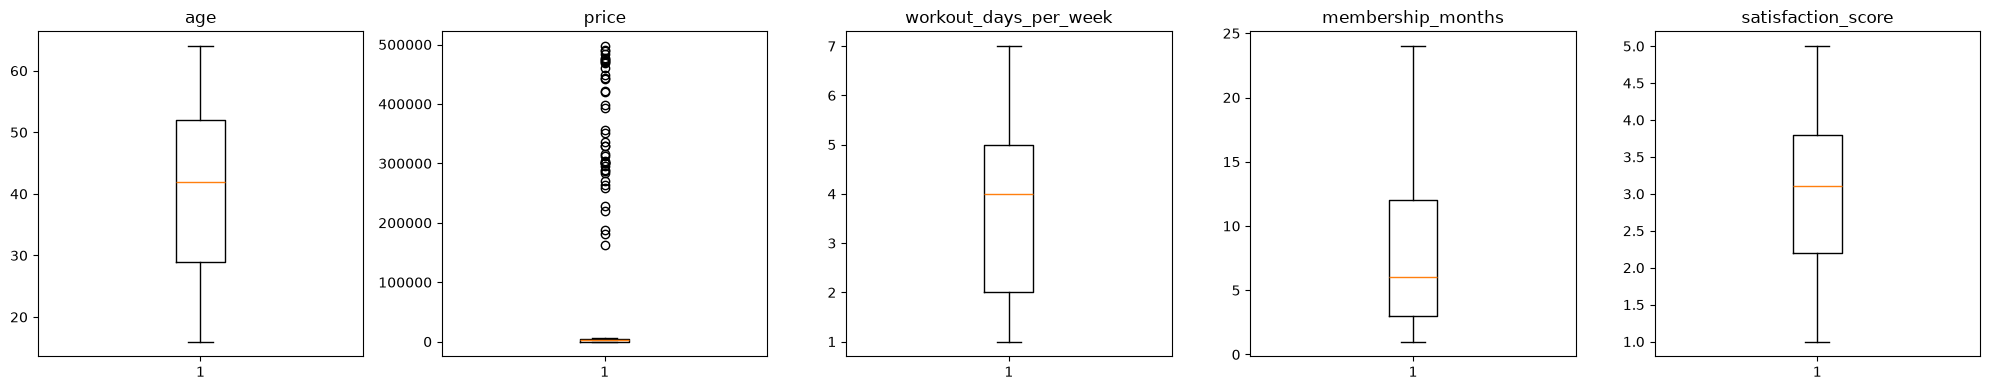

,age,price,workout_days_per_week,membership_months,satisfaction_score
count,400.000000,400.000000,400.000000,400.00000,400.000000
mean,40.517500,39535.972500,3.675000,8.75500,3.024000
std,14.004643,113337.137107,1.615829,7.72523,1.072076
min,16.000000,15.000000,1.000000,1.00000,1.000000
25%,29.000000,56.000000,2.000000,3.00000,2.200000
50%,42.000000,2811.000000,4.000000,6.00000,3.100000
75%,52.000000,4648.000000,5.000000,12.00000,3.800000
max,64.000000,497336.000000,7.000000,24.00000,5.000000


In [22]:
import matplotlib.pyplot as plt

numeric_cols = ['age', 'price', 'workout_days_per_week', 'membership_months', 'satisfaction_score']

fig, axes = plt.subplots(1, len(numeric_cols), figsize=(20, 4))
for ax, col in zip(axes, numeric_cols):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
plt.tight_layout()
plt.show()

df[numeric_cols].describe()


Use IQR to flag outliers — print how many rows each column would flag before deciding to drop or cap anything. Don't drop rows just because a boxplot has whiskers; only act on values that are actually impossible or clearly broken (e.g. negative age already handled, but check for age > 100, or price that's an order of magnitude off after the currency fix).

In [23]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

for col in numeric_cols:
    low, high = iqr_bounds(df[col])
    n_outliers = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: bounds=({low:.1f}, {high:.1f}), outliers={n_outliers}")


age: bounds=(-5.5, 86.5), outliers=0
price: bounds=(-6832.0, 11536.0), outliers=42
workout_days_per_week: bounds=(-2.5, 9.5), outliers=0
membership_months: bounds=(-10.5, 25.5), outliers=0
satisfaction_score: bounds=(-0.2, 6.2), outliers=0


In [24]:
# Cap rather than delete rows (deleting loses signal in a 415-row dataset).
# Only cap columns where the outliers are implausible, not just "high" -
# e.g. price after currency conversion can legitimately vary a lot.
for col in ['age', 'price']:  # adjust this list based on what the IQR/boxplot output showed you
    low, high = iqr_bounds(df[col])
    df[col] = df[col].clip(lower=low, upper=high)

df[numeric_cols].describe()


,age,price,workout_days_per_week,membership_months,satisfaction_score
count,400.000000,400.000000,400.000000,400.00000,400.000000
mean,40.517500,3268.395000,3.675000,8.75500,3.024000
std,14.004643,3451.585017,1.615829,7.72523,1.072076
min,16.000000,15.000000,1.000000,1.00000,1.000000
25%,29.000000,56.000000,2.000000,3.00000,2.200000
50%,42.000000,2811.000000,4.000000,6.00000,3.100000
75%,52.000000,4648.000000,5.000000,12.00000,3.800000
max,64.000000,11536.000000,7.000000,24.00000,5.000000


## Encode categoricals + build X / y

In [25]:
cat_cols = ['gender', 'city', 'membership_type', 'personal_trainer', 'referral_signup']
df_model = pd.get_dummies(df, columns=cat_cols, drop_first=True)

X = df_model.drop(columns=['renewed', 'customer_id'])
y = df_model['renewed']

X.shape, y.value_counts(normalize=True)


((400, 18),
 renewed
 1    0.58
 0    0.42
 Name: proportion, dtype: float64)

Check `y.value_counts(normalize=True)` above — if renewal is heavily imbalanced (e.g. 85/15), plain accuracy will be misleading later; use `class_weight='balanced'` in the model and check precision/recall, not just accuracy.

## Train/test split + scale

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## Fit logistic regression

In [27]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]


## Evaluate

In [28]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print()
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))


Accuracy: 0.5375
Precision: 0.6
Recall: 0.5869565217391305
F1: 0.5934065934065934
ROC-AUC: 0.5473145780051151

[[16 18]
 [19 27]]

              precision    recall  f1-score   support

           0       0.46      0.47      0.46        34
           1       0.60      0.59      0.59        46

    accuracy                           0.54        80
   macro avg       0.53      0.53      0.53        80
weighted avg       0.54      0.54      0.54        80



## Optional: which features matter

Coefficient sign/magnitude on the **scaled** features tells you direction and relative importance (not causal effect).

In [29]:
coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

coef_df


,feature,coefficient
5,gender_female,-0.271303
12,city_Pune,-0.233145
10,city_Hyderabad,-0.194741
13,membership_type_Gold,0.185324
2,workout_days_per_week,-0.156503
7,gender_unknown,-0.138513
9,city_Delhi,-0.108282
14,membership_type_Premium,0.105782
11,city_Mumbai,-0.078786
17,referral_signup_Yes,-0.067248
